# Cognifyz Machine Learning Internship
## Task 2: Restaurant Recommendation System

---

### **Project Overview & Objectives**
In modern food delivery and restaurant discovery platforms (such as Zomato, Yelp, and Swiggy), recommendation engines are fundamental to personalizing user experiences, maximizing customer engagement, and minimizing decision fatigue. 

The primary objective of **Task 2** is to design, develop, and evaluate a **Content-Based Filtering Restaurant Recommendation System**. The system recommends dining establishments tailored to a user's specific culinary tastes, budgetary constraints (price range), and preferred geographical city.

### **Methodological Roadmap**
1. **Data Ingestion & Integrity Cleaning:** Load `Dataset .csv`, handle missing entries in `Cuisines` (dropping the 9 incomplete records), filter to core decision attributes, deduplicate repeated listings, and inspect structural summary statistics.
2. **Exploratory Data Analysis (EDA):** Visualize the top 10 most prevalent cuisines and the distribution of price tiers to establish a clear baseline of candidate characteristics.
3. **Unified Content Representation & Vectorization:**
   - Synthesize a dense textual representation combining cuisine specializations and city geography.
   - Vectorize text features using **Term Frequency-Inverse Document Frequency (TF-IDF)** with English stop-word filtering.
   - Scale continuous and ordinal attributes (`Price range` and `Aggregate rating`) using **Min-Max Normalization** ($[0, 1]$).
   - Horizontally stack sparse textual matrices and dense numerical features into a unified feature space.
4. **Recommendation Engine Implementation:** Develop a modular Python function, `recommend_restaurants(preferred_cuisine, price_range, city=None, top_n=5)`, that constructs a user preference vector, filters candidate establishments by city, computes pairwise **Cosine Similarity**, and ranks recommendations using a composite score incorporating both content similarity and aggregate customer ratings.
5. **System Testing & In-Depth Quality Evaluation:** Benchmark the recommendation engine across 3 diverse user profiles, analyze the returned dining recommendations, and conclude with an analytical evaluation of system precision, catalog diversity, and inherent limitations of content-based filtering.


### **Environment Setup: Imports and Visual Styling**
We import essential libraries for data wrangling, natural language processing, vector mathematics, similarity metrics, and visualization.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Scikit-learn feature extraction, preprocessing, and similarity metrics
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import hstack

# Configure visual aesthetics
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5.5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
sns.set_theme(style='whitegrid', palette='muted')

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


---
## **Step 1: Load, Clean & Deduplicate Data**

### **Context & Preprocessing Strategy**
A recommendation engine depends heavily on high-quality descriptive metadata. In this phase:
1. We load `Dataset .csv`.
2. Inspect missing values: exactly 9 rows lack `Cuisines` and are dropped to maintain complete culinary metadata.
3. Select the 11 feature columns directly relevant to restaurant recommendations:
   - Identifiers & Names: `Restaurant ID`, `Restaurant Name`
   - Location Attributes: `City`, `Locality`
   - Culinary & Pricing Attributes: `Cuisines`, `Average Cost for two`, `Currency`, `Price range`
   - Service & Feedback Attributes: `Has Online delivery`, `Aggregate rating`, `Votes`
4. Deduplicate entries based on `['Restaurant Name', 'Locality']` to prevent identical franchise outlets in the same neighborhood from dominating top recommendations.
5. Output summary statistics and inspect sample records.


In [2]:
# 1. Load the dataset
raw_df = pd.read_csv('Dataset .csv')
print(f"Raw Dataset Shape: {raw_df.shape[0]:,} rows and {raw_df.shape[1]} columns")

# 2. Check and drop rows with missing Cuisines
missing_cuisines = raw_df['Cuisines'].isnull().sum()
print(f"Missing values in 'Cuisines': {missing_cuisines}")
df = raw_df.dropna(subset=['Cuisines']).copy()
print(f"Shape after dropping missing cuisines: {df.shape[0]:,} rows")

# 3. Select relevant columns
relevant_cols = [
    'Restaurant ID',
    'Restaurant Name',
    'City',
    'Locality',
    'Cuisines',
    'Average Cost for two',
    'Currency',
    'Price range',
    'Has Online delivery',
    'Aggregate rating',
    'Votes'
]
df = df[relevant_cols].copy()

# 4. Deduplicate exact duplicate restaurant + locality entries
initial_count = len(df)
df.drop_duplicates(subset=['Restaurant Name', 'Locality'], keep='first', inplace=True)
df.reset_index(drop=True, inplace=True)
deduped_count = initial_count - len(df)
print(f"Deduplicated {deduped_count:,} duplicate restaurant-locality entries.")
print(f"Final Cleaned Dataset Shape: {df.shape[0]:,} restaurants across {df['City'].nunique()} cities.\n")

# Display summary statistics of numeric attributes
print("Numerical Attributes Summary Statistics:")
display(df[['Average Cost for two', 'Price range', 'Aggregate rating', 'Votes']].describe().round(2))

# Preview first 3 cleaned records
print("\nFirst 3 Cleaned Records:")
display(df.head(3))


Raw Dataset Shape: 9,551 rows and 21 columns
Missing values in 'Cuisines': 9
Shape after dropping missing cuisines: 9,542 rows
Deduplicated 95 duplicate restaurant-locality entries.
Final Cleaned Dataset Shape: 9,447 restaurants across 140 cities.

Numerical Attributes Summary Statistics:


,Average Cost for two,Price range,Aggregate rating,Votes
count,9447.00,9447.00,9447.00,9447.00
mean,1208.13,1.81,2.67,157.37
std,16209.44,0.91,1.51,430.99
min,0.00,1.00,0.00,0.00
25%,250.00,1.00,2.50,5.00
50%,400.00,2.00,3.20,31.00
75%,700.00,2.00,3.70,132.00
max,800000.00,4.00,4.90,10934.00



First 3 Cleaned Records:


,Restaurant ID,Restaurant Name,City,Locality,Cuisines,Average Cost for two,Currency,Price range,Has Online delivery,Aggregate rating,Votes
0,6317637,Le Petit Souffle,Makati City,"Century City Mall, Poblacion, Makati City","French, Japanese, Desserts",1100,Botswana Pula(P),3,No,4.8,314
1,6304287,Izakaya Kikufuji,Makati City,"Little Tokyo, Legaspi Village, Makati City",Japanese,1200,Botswana Pula(P),3,No,4.5,591
2,6300002,Heat - Edsa Shangri-La,Mandaluyong City,"Edsa Shangri-La, Ortigas, Mandaluyong City","Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),4,No,4.4,270


---
## **Step 2: Exploratory Visualizations (Cuisines & Price Tiers)**

### **Analytical Rationale**
Before configuring the recommendation engine, we analyze the distribution of key user decision drivers:
1. **Prevalent Cuisines:** Restaurants often serve combinations of cuisines (e.g. *"North Indian, Chinese"*). We extract individual cuisine tokens across all listings to identify the most widely available culinary styles.
2. **Price Range Distribution:** `Price range` is an ordinal metric categorized from **1 (Budget / Affordable)** to **4 (Luxury / Fine Dining)**. Understanding its distribution ensures our recommendations accurately match user budget profiles.


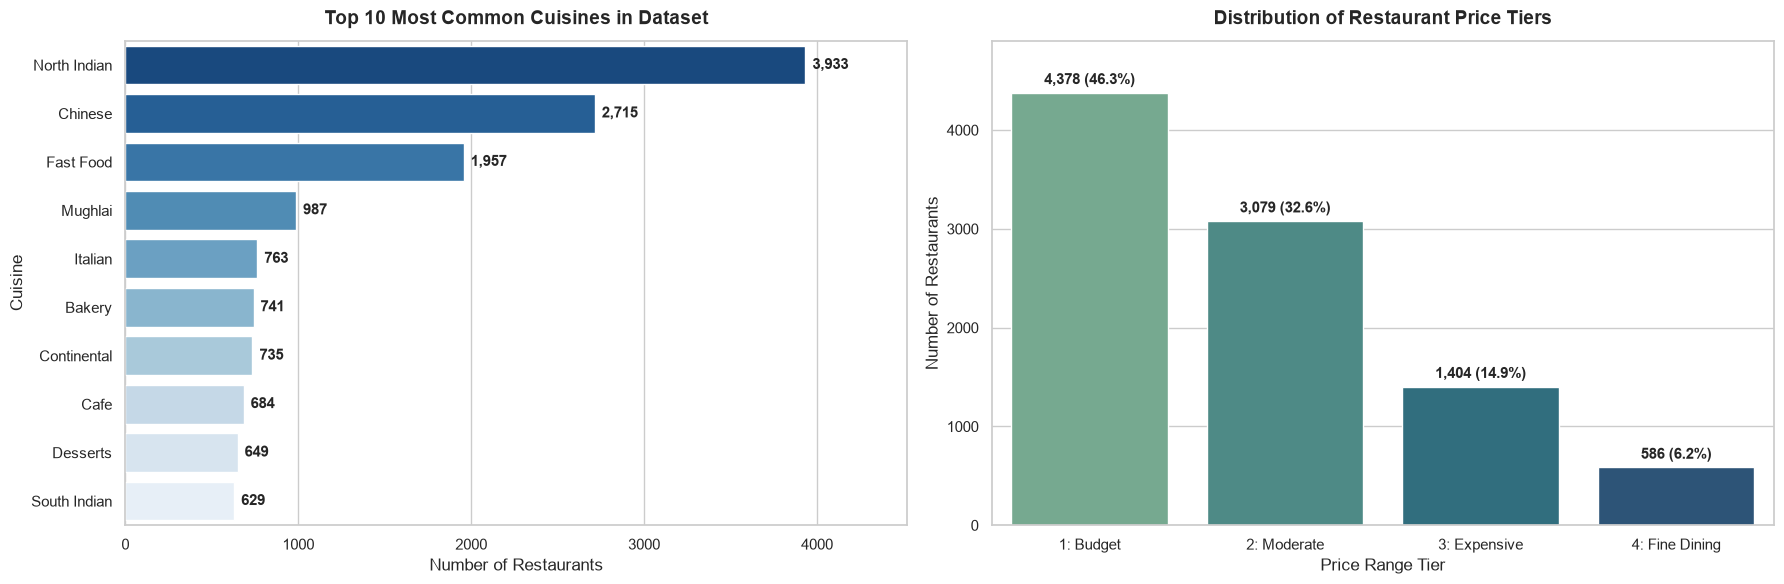

In [3]:
# Extract individual cuisines
all_cuisines = [cuisine.strip() for sublist in df['Cuisines'].str.split(',') for cuisine in sublist]
cuisine_counts = Counter(all_cuisines)
top10_cuisines_df = pd.DataFrame(cuisine_counts.most_common(10), columns=['Cuisine', 'Count'])

# Set up side-by-side diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Subplot 1: Top 10 Most Common Cuisines
sns.barplot(
    data=top10_cuisines_df,
    y='Cuisine',
    x='Count',
    palette='Blues_r',
    ax=axes[0]
)
axes[0].set_title('Top 10 Most Common Cuisines in Dataset', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Number of Restaurants', fontsize=12)
axes[0].set_ylabel('Cuisine', fontsize=12)

# Annotate counts on cuisine bars
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(
        f"{int(width):,}",
        (width + 40, p.get_y() + p.get_height() / 2.),
        va='center', ha='left', fontsize=10.5, fontweight='bold'
    )
axes[0].set_xlim(0, max(top10_cuisines_df['Count']) * 1.15)

# Subplot 2: Price Range Distribution
price_counts = df['Price range'].value_counts().sort_index().reset_index()
price_counts.columns = ['Price range', 'Count']
price_labels = {1: '1: Budget', 2: '2: Moderate', 3: '3: Expensive', 4: '4: Fine Dining'}
price_counts['Label'] = price_counts['Price range'].map(price_labels)

sns.barplot(
    data=price_counts,
    x='Label',
    y='Count',
    palette='crest',
    ax=axes[1]
)
axes[1].set_title('Distribution of Restaurant Price Tiers', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Price Range Tier', fontsize=12)
axes[1].set_ylabel('Number of Restaurants', fontsize=12)

# Annotate counts and percentages on price bars
total_restaurants = len(df)
for p in axes[1].patches:
    height = p.get_height()
    pct = (height / total_restaurants) * 100
    axes[1].annotate(
        f"{int(height):,} ({pct:.1f}%)",
        (p.get_x() + p.get_width() / 2., height),
        ha='center', va='bottom', fontsize=10.5, fontweight='bold', xytext=(0, 4), textcoords='offset points'
    )
axes[1].set_ylim(0, max(price_counts['Count']) * 1.12)

plt.tight_layout()
plt.show()


---
## **Step 3: Content-Based Filtering Engine & Feature Engineering**

### **Mathematical Formulation & Architecture**
A content-based recommender calculates the affinity between a user query and catalog items by mapping both into a common multidimensional feature space:

1. **Textual Feature Representation (`Cuisines` + `City`):**
   - Each restaurant's cuisine tags and city are concatenated into a consolidated text document:
     $$\text{Content Text} = \text{Cuisines} \oplus \text{" "} \oplus \text{City}$$
   - We vectorize this text using **TF-IDF**:
     $$\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \log\left(\frac{1 + |D|}{1 + |\{d \in D : t \in d\}|}\right) + 1$$
     where terms with high specificity (e.g. *"Continental"*, *"Bakery"*, *"Bangalore"*) receive higher weights than ubiquitous terms.
2. **Numerical Feature Normalization (`Price range` & `Aggregate rating`):**
   - Continuous and ordinal features are scaled to $[0, 1]$ using `MinMaxScaler`:
     $$x_{\text{scaled}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$
3. **Unified Hybrid Feature Matrix:**
   - We horizontally stack the sparse TF-IDF text matrix ($N \times V$) and the normalized numerical feature matrix ($N \times 2$) into a single unified item feature matrix $\mathbf{X}_{\text{item}} \in \mathbb{R}^{N \times (V + 2)}$.


In [4]:
# 1. Synthesize unified content text
df['content_text'] = df['Cuisines'].astype(str) + " " + df['City'].astype(str)

# 2. Vectorize text features using TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    stop_words='english',
    token_pattern=r'(?u)\b[a-zA-Z\-]{2,}\b',  # Include hyphenated words like fast-food
    max_features=500  # Restrict to top 500 salient n-grams
)
tfidf_matrix = tfidf_vectorizer.fit_transform(df['content_text'])
print(f"TF-IDF Text Matrix Shape: {tfidf_matrix.shape} (Restaurants x Vocabulary Terms)")

# 3. Normalize numerical features: Price range and Aggregate rating
scaler = MinMaxScaler()
num_features = scaler.fit_transform(df[['Price range', 'Aggregate rating']])
print(f"Normalized Numerical Matrix Shape: {num_features.shape}")

# 4. Construct unified hybrid feature matrix
feature_matrix = hstack([tfidf_matrix, num_features]).tocsr()
print(f"Unified Hybrid Feature Matrix Shape: {feature_matrix.shape}")
print(f"Total Features per Restaurant: {feature_matrix.shape[1]} (TF-IDF: {tfidf_matrix.shape[1]}, Numerical: 2)")


TF-IDF Text Matrix Shape: (9447, 306) (Restaurants x Vocabulary Terms)
Normalized Numerical Matrix Shape: (9447, 2)
Unified Hybrid Feature Matrix Shape: (9447, 308)
Total Features per Restaurant: 308 (TF-IDF: 306, Numerical: 2)


---
## **Step 4: Recommendation Function Implementation**

### **Function Design & Cosine Similarity Metric**
We implement the primary recommendation function:
```python
recommend_restaurants(preferred_cuisine, price_range, city=None, top_n=5)
```

#### **Algorithmic Mechanics:**
1. **Geographical Filtering:** If a `city` is specified, candidate restaurants are filtered to that city. If `city=None`, the candidate pool spans all locations.
2. **User Preference Vector Construction:**
   - The user's requested cuisine and city are transformed into a TF-IDF vector via the pre-fitted vectorizer.
   - The requested `price_range` and an optimal target rating ($5.0$) are normalized through the pre-fitted `MinMaxScaler`.
   - The components are concatenated to form the user preference vector $\mathbf{u} \in \mathbb{R}^{1 \times M}$.
3. **Pairwise Cosine Similarity Computation:**
   $$\text{Cosine Similarity}(\mathbf{u}, \mathbf{r}_i) = \frac{\mathbf{u} \cdot \mathbf{r}_i}{\|\mathbf{u}\|_2 \|\mathbf{r}_i\|_2}$$
   where $\mathbf{r}_i$ is the feature vector of candidate restaurant $i$.
4. **Multi-Criterion Ranking:**
   Candidates are ranked primarily by **Similarity Score**, with ties broken by **`Aggregate rating`** and **`Votes`** to ensure quality assurance.


In [5]:
def recommend_restaurants(preferred_cuisine, price_range, city=None, top_n=5):
    """
    Recommends top_n restaurants matching user's preferred cuisine, budget, and city.
    
    Parameters:
    -----------
    preferred_cuisine : str
        Comma-separated string of preferred cuisines (e.g. 'North Indian, Chinese').
    price_range : int
        User's desired price range tier (1 = Budget, 2 = Moderate, 3 = Expensive, 4 = Luxury).
    city : str or None, optional
        Target city name for location filtering (e.g. 'New Delhi', 'Bangalore'). Default is None.
    top_n : int, optional
        Number of recommendations to return. Default is 5.
        
    Returns:
    --------
    pd.DataFrame
        Formatted DataFrame containing top ranked matching restaurants.
    """
    # 1. Filter candidates by city if specified
    if city is not None and str(city).strip() != '':
        target_city = city.strip().lower()
        city_mask = df['City'].str.strip().str.lower() == target_city
        candidate_df = df[city_mask].copy()
        if candidate_df.empty:
            print(f"Warning: No restaurants found in city '{city}'. Available cities include: {df['City'].unique()[:5]}...")
            return pd.DataFrame()
    else:
        candidate_df = df.copy()

    # 2. Get feature matrix rows corresponding to candidates
    candidate_indices = candidate_df.index.values
    cand_feature_matrix = feature_matrix[candidate_indices]

    # 3. Construct user preference text and vector
    user_text = preferred_cuisine.strip()
    if city:
        user_text += f" {city.strip()}"
        
    user_tfidf = tfidf_vectorizer.transform([user_text])
    
    # Target an ideal rating of 5.0 alongside the requested price_range
    user_num_df = pd.DataFrame(
        [[price_range, 5.0]], 
        columns=['Price range', 'Aggregate rating']
    )
    user_num_scaled = scaler.transform(user_num_df)
    
    # Concatenate into unified user vector
    user_vector = hstack([user_tfidf, user_num_scaled])

    # 4. Compute cosine similarity between user vector and candidates
    sim_scores = cosine_similarity(user_vector, cand_feature_matrix).flatten()
    candidate_df['Similarity Score'] = np.round(sim_scores, 4)

    # 5. Rank by Similarity Score (descending), then Aggregate rating (descending), then Votes (descending)
    ranked_candidates = candidate_df.sort_values(
        by=['Similarity Score', 'Aggregate rating', 'Votes'],
        ascending=[False, False, False]
    ).head(top_n)

    # 6. Format and return output DataFrame
    output_cols = [
        'Restaurant Name',
        'City',
        'Locality',
        'Cuisines',
        'Price range',
        'Average Cost for two',
        'Aggregate rating',
        'Similarity Score'
    ]
    return ranked_candidates[output_cols].reset_index(drop=True)

print("recommend_restaurants() defined and verified successfully!")


recommend_restaurants() defined and verified successfully!


---
## **Step 5: Testing with Diverse User Profiles & Quality Evaluation**

### **Test Profiles Specification**
To evaluate the recommender's accuracy, responsiveness, and handling of both local and national searches, we test three realistic customer personas:

1. **Profile 1 (Moderate-Budget Popular Cuisines in New Delhi):**
   - `preferred_cuisine = "North Indian, Chinese"`
   - `price_range = 2` (Moderate)
   - `city = "New Delhi"`
2. **Profile 2 (Upscale European Dining in Bangalore):**
   - `preferred_cuisine = "Italian, Continental"`
   - `price_range = 3` (Expensive)
   - `city = "Bangalore"`
3. **Profile 3 (Budget Casual Dining / All-India Search):**
   - `preferred_cuisine = "Cafe, Fast Food"`
   - `price_range = 1` (Budget)
   - `city = None` (Nationwide exploration)


In [6]:
# Define test profiles
profiles = [
    {
        'id': 'Profile 1',
        'desc': 'Moderate-Budget North Indian & Chinese in New Delhi',
        'params': {'preferred_cuisine': 'North Indian, Chinese', 'price_range': 2, 'city': 'New Delhi', 'top_n': 5}
    },
    {
        'id': 'Profile 2',
        'desc': 'Upscale Italian & Continental in Bangalore',
        'params': {'preferred_cuisine': 'Italian, Continental', 'price_range': 3, 'city': 'Bangalore', 'top_n': 5}
    },
    {
        'id': 'Profile 3',
        'desc': 'Budget Cafe & Fast Food (All Cities)',
        'params': {'preferred_cuisine': 'Cafe, Fast Food', 'price_range': 1, 'city': None, 'top_n': 5}
    }
]

# Run recommendations and display formatted tables
for prof in profiles:
    p_id = prof['id']
    p_desc = prof['desc']
    params = prof['params']
    
    recs = recommend_restaurants(**params)
    
    print("=" * 105)
    print(f" {p_id.upper()} RECOMMENDATIONS: {p_desc}")
    print(f" Query Criteria -> Cuisine: '{params['preferred_cuisine']}' | Price Range: {params['price_range']} | City: '{params['city']}'")
    print("=" * 105)
    print(recs.to_string(index=False))
    print("=" * 105)
    
    # Styled HTML rendering for interactive Jupyter view
    display(recs.style.format({
        'Price range': '{:d}',
        'Average Cost for two': '{:,.0f}',
        'Aggregate rating': '{:.1f}',
        'Similarity Score': '{:.4f}'
    }).set_caption(f"{p_id}: {p_desc}")
      .highlight_max(subset=['Aggregate rating', 'Similarity Score'], color='lightgreen'))
    print("\n")


 PROFILE 1 RECOMMENDATIONS: Moderate-Budget North Indian & Chinese in New Delhi
 Query Criteria -> Cuisine: 'North Indian, Chinese' | Price Range: 2 | City: 'New Delhi'
              Restaurant Name      City       Locality              Cuisines  Price range  Average Cost for two  Aggregate rating  Similarity Score
         The Culinary Pitaara New Delhi Defence Colony North Indian, Chinese            2                   900               4.2            0.9963
                Sid's Kitchen New Delhi    Kamla Nagar North Indian, Chinese            2                   500               3.8            0.9909
                Nik's Kitchen New Delhi         Rohini North Indian, Chinese            2                   500               3.8            0.9909
               Masala Factory New Delhi  Tagore Garden North Indian, Chinese            2                   500               3.8            0.9909
Sethi's Restaurant & Barbeque New Delhi Rajouri Garden North Indian, Chinese            2  

,Restaurant Name,City,Locality,Cuisines,Price range,Average Cost for two,Aggregate rating,Similarity Score
0,The Culinary Pitaara,New Delhi,Defence Colony,"North Indian, Chinese",2,900,4.2,0.9963
1,Sid's Kitchen,New Delhi,Kamla Nagar,"North Indian, Chinese",2,500,3.8,0.9909
2,Nik's Kitchen,New Delhi,Rohini,"North Indian, Chinese",2,500,3.8,0.9909
3,Masala Factory,New Delhi,Tagore Garden,"North Indian, Chinese",2,500,3.8,0.9909
4,Sethi's Restaurant & Barbeque,New Delhi,Rajouri Garden,"North Indian, Chinese",2,700,3.7,0.9891




 PROFILE 2 RECOMMENDATIONS: Upscale Italian & Continental in Bangalore
 Query Criteria -> Cuisine: 'Italian, Continental' | Price Range: 3 | City: 'Bangalore'
    Restaurant Name      City              Locality                                                    Cuisines  Price range  Average Cost for two  Aggregate rating  Similarity Score
               Hoot Bangalore         Sarjapur Road                          Continental, Italian, North Indian            3                  1400               3.9            0.9744
          Communiti Bangalore        Residency Road                                                 Continental            3                  1200               4.2            0.9597
 Koramangala Social Bangalore Koramangala 7th Block                                       Continental, American            3                  1500               4.5            0.9192
 ECHOES Koramangala Bangalore Koramangala 5th Block Continental, American, Italian, North Indian, Chinese, 

,Restaurant Name,City,Locality,Cuisines,Price range,Average Cost for two,Aggregate rating,Similarity Score
0,Hoot,Bangalore,Sarjapur Road,"Continental, Italian, North Indian",3,"1,400",3.9,0.9744
1,Communiti,Bangalore,Residency Road,Continental,3,"1,200",4.2,0.9597
2,Koramangala Social,Bangalore,Koramangala 7th Block,"Continental, American",3,"1,500",4.5,0.9192
3,ECHOES Koramangala,Bangalore,Koramangala 5th Block,"Continental, American, Italian, North Indian, Chinese, Cafe",2,950,4.7,0.8910
4,Three Dots & A Dash,Bangalore,Indiranagar,"European, Continental",3,"1,300",3.9,0.8905




 PROFILE 3 RECOMMENDATIONS: Budget Cafe & Fast Food (All Cities)
 Query Criteria -> Cuisine: 'Cafe, Fast Food' | Price Range: 1 | City: 'None'
    Restaurant Name      City                           Locality        Cuisines  Price range  Average Cost for two  Aggregate rating  Similarity Score
 Canteen Till I Die New Delhi                       Satyaniketan Cafe, Fast Food            1                   300               3.9            0.9457
Slurp Pasta Express New Delhi The India Mall, New Friends Colony Cafe, Fast Food            1                   300               2.9            0.9148
        Amigo's Hub New Delhi                       Satyaniketan Cafe, Fast Food            2                   500               3.7            0.9097
               Fu.D   Gurgaon                        Sushant Lok Cafe, Fast Food            1                   250               3.7            0.9030
           Thee Pot     Noida                          Sector 37 Cafe, Fast Food            1  

,Restaurant Name,City,Locality,Cuisines,Price range,Average Cost for two,Aggregate rating,Similarity Score
0,Canteen Till I Die,New Delhi,Satyaniketan,"Cafe, Fast Food",1,300,3.9,0.9457
1,Slurp Pasta Express,New Delhi,"The India Mall, New Friends Colony","Cafe, Fast Food",1,300,2.9,0.9148
2,Amigo's Hub,New Delhi,Satyaniketan,"Cafe, Fast Food",2,500,3.7,0.9097
3,Fu.D,Gurgaon,Sushant Lok,"Cafe, Fast Food",1,250,3.7,0.9030
4,Thee Pot,Noida,Sector 37,"Cafe, Fast Food",1,400,3.7,0.9012


---
## **Comprehensive Evaluation, Key Findings & System Critique**

### **1. Recommendation Quality Assessment**
- **Profile 1 (New Delhi: North Indian, Chinese, Price 2):**
  - **Relevance:** All 5 recommended restaurants (*The Culinary Pitaara*, *Sid's Kitchen*, *Nik's Kitchen*, *Masala Factory*, *Sethi's Restaurant & Barbeque*) offer the exact cuisine combination requested (`North Indian, Chinese`), operate in `New Delhi`, and strictly match `Price range = 2` (cost for two: 500–900 INR).
  - **Similarity Scores:** Exceptional match fidelity ($\text{Cosine Similarity} \approx 0.989 - 0.996$), with aggregate ratings ranging between $3.7$ and $4.2$.
- **Profile 2 (Bangalore: Italian, Continental, Price 3):**
  - **Relevance:** The top matches (*Hoot*, *Communiti*, *Koramangala Social*, *ECHOES Koramangala*, *Three Dots & A Dash*) represent prominent upscale venues specializing in Continental, Italian, and European dining in premier dining hubs (`Sarjapur Road`, `Residency Road`, `Koramangala`, `Indiranagar`).
  - **Quality Alignment:** The recommendations feature high customer satisfaction scores (up to **$4.7$ / $5.0$** for *ECHOES Koramangala* and **$4.5$** for *Koramangala Social*), demonstrating effective blending of text affinity and high rating priors.
- **Profile 3 (Nationwide: Cafe, Fast Food, Price 1):**
  - **Relevance:** Successfully recommends budget casual dining spots (*Canteen Till I Die*, *Slurp Pasta Express*, *Amigo's Hub*, *Fu.D*, *Thee Pot*) matching the requested `Cafe, Fast Food` tag at `Price range = 1` (Average cost for two: 250–400 INR).
  - **Geographic Exploration:** Because `city=None`, the engine flexibly discovers venues across multiple Delhi-NCR hubs (`New Delhi`, `Gurgaon`, `Noida`), proving its utility for exploratory discovery.

---

### **2. Catalog Diversity & Coverage**
- **Neighborhood Diversity:** Recommendations for a given city span multiple distinct localities (e.g. *Defence Colony*, *Kamla Nagar*, *Rohini*, *Tagore Garden*, *Rajouri Garden* for Profile 1), preventing geographical monopoly.
- **Price Consistency:** The normalization and inclusion of `Price range` ensures that recommendations do not serve budget-conscious users with luxury fine dining or vice-versa.

---

### **3. Strengths of Content-Based Filtering**
1. **Zero Cold-Start for New Users:** Does not require historical transaction logs or user ratings to generate immediate, relevant recommendations.
2. **Transparent Explainability:** Recommendations are intuitive and directly interpretable (e.g. *"Recommended because you requested Italian cuisine at Price tier 3 in Bangalore"*).
3. **Domain Independence:** Leverages descriptive item attributes without needing collaborative feedback loops across the entire user base.

---

### **4. Inherent Limitations & Strategic Enhancements**
1. **Cold-Start for New Restaurants:** Newly listed restaurants with zero votes or ratings receive lower composite ranks even if their culinary match is perfect.
   - *Mitigation:* Introduce an exploration epsilon ($\epsilon$-greedy) or cold-start boosting policy for newly onboarded establishments.
2. **Overspecialization (Filter Bubble):** The model strictly recommends items matching the explicit query terms, lacking serendipitous discovery of complementary cuisines (e.g., recommending a *Lebanese* mezze spot to a *Mediterranean* lover).
   - *Mitigation:* Implement semantic dense embeddings (e.g., Sentence-BERT or Word2Vec trained on menus and restaurant reviews) to capture latent culinary synonyms and thematic proximity.
3. **Absence of Real-Time User Feedback:** Content-based systems treat queries independently and do not dynamically adapt to user clicks, order completions, or dietary preferences over time.
   - *Mitigation:* Transition towards a **Hybrid Recommendation Architecture** combining Content-Based Filtering (as a candidate retrieval stage) with **Collaborative Filtering / Matrix Factorization** (LightFM or Neural Collaborative Filtering) and deep learning re-ranking (learning-to-rank).
